# Initialize the Model and Dataset for testing

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UNetBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        # Encoder
        self.enc1 = UNetBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = UNetBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = UNetBlock(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = UNetBlock(256, 512)

        # Decoder
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = UNetBlock(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = UNetBlock(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = UNetBlock(128, 64)

        # Output
        self.out_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        # Bottleneck
        bn = self.bottleneck(self.pool3(e3))

        # Decoder
        d3 = self.dec3(torch.cat([self.up3(bn), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        out = torch.sigmoid(self.out_conv(d1))
        return out


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet().to(device)


In [6]:
model.load_state_dict(torch.load("unet_epoch_20_fulldataset_augmented_lits_chaos_seeded.pth"));
model.to(device);


In [8]:
import os
import cv2
import torch
from torch.utils.data import Dataset
import numpy as np

class LITSSliceDataset(Dataset):
    def __init__(self, image_dirs, mask_root, transform=None):
        self.image_paths = []
        self.mask_root = mask_root
        self.transform = transform

        for folder in image_dirs:
            self.image_paths.extend(sorted([
                os.path.join(folder, f)
                for f in os.listdir(folder)
                if f.endswith(".png")
            ]))

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        fname = os.path.basename(image_path)
    
        vol_id, slice_id = fname.replace(".png", "").split("_")[1], fname.replace(".png", "").split("_")[3]
        mask_path = os.path.join(self.mask_root, f"volume_{vol_id}", f"mask_{vol_id}_slice_{slice_id}.png")
    
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
    
        image = np.expand_dims(image, axis=-1)  # [H, W, 1]
        mask = np.expand_dims(mask, axis=-1)    # [H, W, 1]
    
        augmented = self.transform(image=image, mask=mask)
        image = augmented["image"]              # [1, H, W]
        mask = augmented["mask"]                # Should now also be [1, H, W]

        if mask.ndim == 4:
            mask = mask.permute(0, 3, 1, 2).squeeze(0)
        elif mask.ndim == 3 and mask.shape[0] != 1:
            mask = mask.permute(2, 0, 1)
        
        return image, mask

    def __len__(self):
        return len(self.image_paths)



In [10]:
import os
import cv2
import numpy as np
import torch
import re
from torch.utils.data import Dataset

class CHAOSSliceDataset(Dataset):
    def __init__(self, image_dir, mask_root, transform=None):
        self.image_dir = image_dir
        self.mask_root = mask_root
        self.transform = transform
        self.missing_count = 0  # ✅ Track missing masks

        self.image_paths = sorted([
            os.path.join(image_dir, f)
            for f in os.listdir(image_dir)
            if f.endswith(".png")
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        try:
            image_path = self.image_paths[idx]
            fname = os.path.basename(image_path)

            # Extract patient ID and slice number
            parts = fname.replace(".png", "").split("_")
            patient_id = parts[1]

            img_match = re.search(r'i(\d{3,})', fname) or re.search(r'IMG-\d{4}-(\d{3,})', fname)
            if img_match:
                slice_num = int(img_match.group(1))
            else:
                slice_num = int(re.findall(r'\d+', fname)[-1])
            slice_str = f"{slice_num:03d}"

            mask_path = os.path.join(self.mask_root, patient_id, "Ground", f"liver_GT_{slice_str}.png")

            # Load image and mask
            img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

            if img is None or mask is None:
                raise FileNotFoundError

            img = img.astype(np.float32) / 255.0
            mask = mask.astype(np.float32) / 255.0

            img = np.expand_dims(img, axis=-1)
            mask = np.expand_dims(mask, axis=-1)

            if self.transform:
                augmented = self.transform(image=img, mask=mask)
                img = augmented["image"]
                mask = augmented["mask"]
                if mask.ndim == 3 and mask.shape[-1] == 1:
                    mask = mask.squeeze(-1).unsqueeze(0)

            return img, mask

        except FileNotFoundError:
            self.missing_count += 1
            new_idx = (idx + 1) % len(self.image_paths)
            return self.__getitem__(new_idx)



In [12]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.Affine(scale=(0.95, 1.05), translate_percent=(0.05, 0.05), rotate=0, p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.GaussNoise(std_range=(0.01, 0.05), mean_range=(0.0, 0.0), p=0.3),
    A.ElasticTransform(alpha=1, sigma=50, p=0.2),
    A.GridDistortion(num_steps=5, distort_limit=0.03, p=0.2),
    A.CoarseDropout(num_holes_range=(1, 1), hole_height_range=(10, 20), hole_width_range=(10, 20), fill=0, fill_mask=0, p=0.3),
    A.CLAHE(clip_limit=2.0, p=0.3),
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
], additional_targets={'mask': 'mask'})


C:\Users\Student\AppData\Roaming\Python\Python312\site-packages\albumentations\__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.7'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [13]:

full_dataset = LITSSliceDataset(
    image_dirs=["LITS/1_liver/"],
    mask_root="LITS_masks/",
)


In [14]:
from torch.utils.data import random_split

train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
transform=train_transform  # Use augmentation for training

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])


In [18]:
from torch.utils.data import DataLoader


val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=0.0, std=1.0, max_pixel_value=1.0),
    ToTensorV2()
])

# Apply val_transform manually to test set
test_dataset.dataset.transform = val_transform

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)


In [20]:
import random
import matplotlib.pyplot as plt

test_dataset.dataset.transform = val_transform

def visualize_random_prediction(model, dataset, device):
    model.eval()
    
    # Pick a random sample from test set
    idx = random.randint(0, len(dataset) - 1)
    img, gt_mask = dataset[idx]

    # Move to device and predict
    img_batch = img.unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(img_batch).squeeze().cpu().numpy()
    
    img_np = img.squeeze().cpu().numpy()
    gt_np = gt_mask.squeeze().cpu().numpy()
    pred_binary = (pred > 0.5).astype(np.uint8)

    # Plot the three visualizations
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    # 1. CT + Predicted Mask
    ax[0].imshow(img_np, cmap='gray')
    ax[0].imshow(pred_binary, cmap='Reds', alpha=0.4)
    ax[0].set_title("Predicted Mask Overlay")
    ax[0].axis('off')

    # 2. CT + Ground Truth Mask
    ax[1].imshow(img_np, cmap='gray')
    ax[1].imshow(gt_np, cmap='Blues', alpha=0.4)
    ax[1].set_title("Ground Truth Mask Overlay")
    ax[1].axis('off')

    # 3. Raw CT Image
    ax[2].imshow(img_np, cmap='gray')
    ax[2].set_title("Original Liver CT Slice")
    ax[2].axis('off')

    plt.tight_layout()
    plt.show()

    return pred_binary, img_np, gt_mask

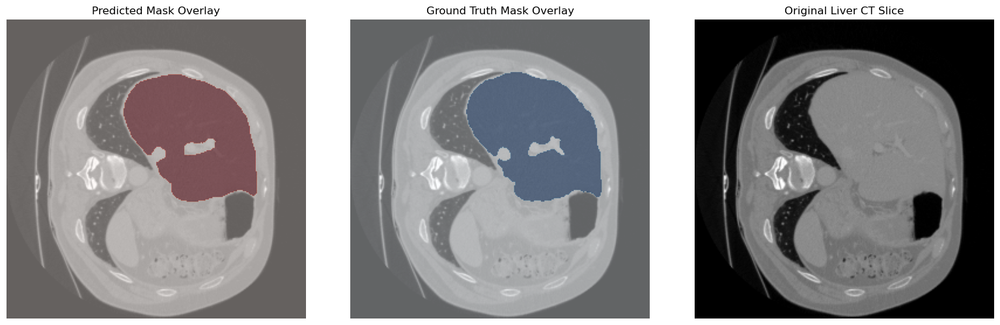

In [21]:
pred_binary, img_resized, gt_mask = visualize_random_prediction(model, test_dataset, device)


# Prepare combined dataset for chaos and lits for evaluation

In [25]:
from torch.utils.data import ConcatDataset

# LiTS Dataset
lits_dataset = LITSSliceDataset(
    image_dirs=["LITS/1_liver"],
    mask_root="LITS_masks/",
    transform=train_transform  # reuse same augmentation
)

# CHAOS Dataset
chaos_dataset = CHAOSSliceDataset(
    image_dir="../chaos_dataset/1_liver",
    mask_root="../chaos/Train_Sets/CT",
    transform=train_transform
)

# Combine them

combined_dataset = ConcatDataset([lits_dataset, chaos_dataset])



In [27]:
from torch.utils.data import WeightedRandomSampler

# Count how many samples per dataset
n_lits = len(lits_dataset)
n_chaos = len(chaos_dataset)

# Create weights: inverse of dataset size
weights = [1.0 / n_lits] * n_lits + [1.0 / n_chaos] * n_chaos

# Sampler will draw samples such that both datasets contribute equally
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)


In [29]:
from torch.utils.data import random_split
import torch

# Define split sizes
train_size = int(0.9 * len(combined_dataset))
test_size = len(combined_dataset) - train_size

# Set a generator with a fixed seed
generator = torch.Generator().manual_seed(42)

# Perform the seeded split
combined_train, combined_test = random_split(combined_dataset, [train_size, test_size], generator=generator)


# Start of Level Set Methods

## Erode Masks to prepare for Level set methods

In [33]:
from scipy.ndimage import distance_transform_edt

def mask_to_signed_distance(mask):
    """
    Converts a binary mask to a signed distance function (φ).
    Inside = negative, boundary = 0, outside = positive.
    """
    mask = mask.astype(np.uint8)

    # Distance to background from inside (negative)
    dist_inside = distance_transform_edt(mask)
    # Distance to foreground from outside (positive)
    dist_outside = distance_transform_edt(1 - mask)

    # Signed distance function: inside negative, outside positive
    phi = dist_outside - dist_inside

    return phi


In [35]:
import cv2

def erode_mask(mask, iterations=5):
    kernel = np.ones((5, 5), np.uint8)
    return cv2.erode(mask.astype(np.uint8), kernel, iterations=iterations)


inner_mask = erode_mask(pred_binary, iterations=5)
phi_init = mask_to_signed_distance(inner_mask)


In [37]:
import matplotlib.pyplot as plt

def compare_masks_overlay(image, pred_mask, eroded_mask):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Original predicted mask
    ax[0].imshow(image, cmap='gray')
    ax[0].imshow(pred_mask, cmap='Reds', alpha=0.4)
    ax[0].set_title("Original Predicted Mask")
    ax[0].axis('off')

    # Eroded version
    ax[1].imshow(image, cmap='gray')
    ax[1].imshow(eroded_mask, cmap='Blues', alpha=0.4)
    ax[1].set_title("Eroded Predicted Mask")
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()


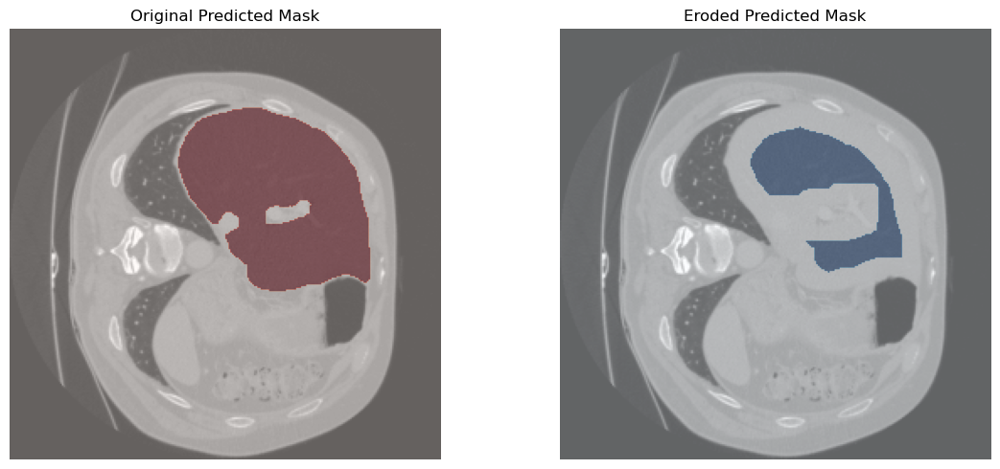

In [39]:
compare_masks_overlay(img_resized, pred_binary, inner_mask)


## Extract GLCM MAP

In [42]:
from skimage.feature import graycomatrix, graycoprops
from skimage.util import view_as_windows
import numpy as np

def compute_glcm_feature_maps(image, window_size=7, distances=[1], angles=[0], levels=32):
    """
    Computes multiple GLCM feature maps over the image using a sliding window.
    Returns a dict of feature_name → 2D array.
    """
    image = (image * (levels - 1)).astype(np.uint8)
    pad = window_size // 2
    padded = np.pad(image, pad, mode='reflect')

    h, w = image.shape
    feature_maps = {
        "contrast": np.zeros((h, w), dtype=np.float32),
        "homogeneity": np.zeros((h, w), dtype=np.float32),
    }

    for i in range(pad, pad + h):
        for j in range(pad, pad + w):
            window = padded[i - pad:i + pad + 1, j - pad:j + pad + 1]
            glcm = graycomatrix(window, distances=distances, angles=angles,
                                levels=levels, symmetric=True, normed=True)

            feature_maps["contrast"][i - pad, j - pad] = graycoprops(glcm, 'contrast')[0, 0]
            feature_maps["homogeneity"][i - pad, j - pad] = graycoprops(glcm, 'homogeneity')[0, 0]


    return feature_maps


In [44]:
import matplotlib.pyplot as plt

def visualize_glcm_maps(image, glcm_maps):
    """
    Displays the original image and all computed GLCM maps.
    """
    plt.figure(figsize=(18, 10))

    # Plot original image
    plt.subplot(2, 3, 1)
    plt.imshow(image, cmap='gray')
    plt.title("Original CT")
    plt.axis('off')

    # Plot each GLCM feature map
    feature_names = ["contrast", "homogeneity"]
    for i, name in enumerate(feature_names, start=2):
        plt.subplot(2, 3, i)
        plt.imshow(glcm_maps[name], cmap='hot')
        plt.title(f"GLCM {name.capitalize()}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [46]:
feature_maps = compute_glcm_feature_maps(img_resized)

# Normalize homogeneity
homogeneity_map = feature_maps["homogeneity"]
homogeneity_map = (homogeneity_map - homogeneity_map.min()) / (homogeneity_map.max() - homogeneity_map.min() + 1e-8)

# Optional smoothing
# from scipy.ndimage import gaussian_filter
# homogeneity_map = gaussian_filter(homogeneity_map, sigma=1)

# Replace in feature_maps if needed
feature_maps["homogeneity"] = homogeneity_map


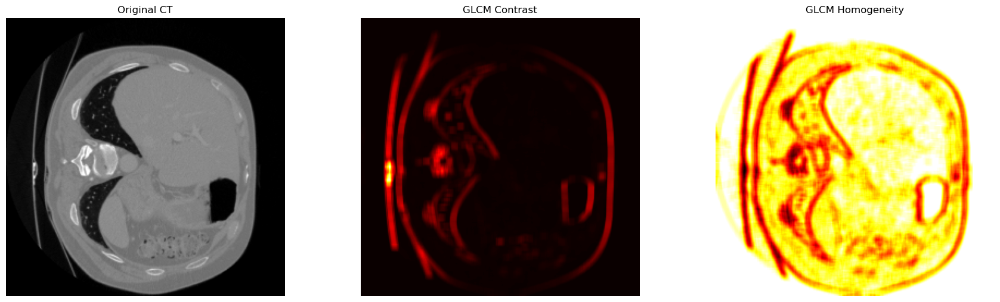

In [47]:
visualize_glcm_maps(img_resized, feature_maps)

## Level Set Methods

### Failure Curvature Regularization

In [50]:
import numpy as np
from scipy.ndimage import laplace, gaussian_filter

def compute_curvature(phi):
    """
    Computes curvature of the level set function φ.
    """
    phi_x = np.gradient(phi, axis=1)
    phi_y = np.gradient(phi, axis=0)
    norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)

    nxx = np.gradient(phi_x / norm, axis=1)
    nyy = np.gradient(phi_y / norm, axis=0)
    curvature = nxx + nyy
    return curvature

def update_phi(phi, contrast, homogeneity, alpha=1.0, beta=1.0, gamma=0.2, timestep=1.0):
    """
    Update φ using the PDE from the paper with texture forces and curvature.
    """
    kappa = compute_curvature(phi)

    # External force: texture-driven
    F_ext = alpha * contrast - beta * homogeneity

    # Total update
    dphi_dt = F_ext - gamma * kappa

    # Gradient descent step
    phi_new = phi + timestep * dphi_dt

    return phi_new


In [51]:
def evolve_level_set(phi, contrast_map, homogeneity_map, img_resized, gt_mask,
                     alpha=1.0, beta=1.0, gamma=1.0,
                     timestep=0.1, iterations=200, visualize_every=10,
                     force_mask=None):
    """
    Evolve φ using texture-based level set with curvature regularization.
    Optional: restrict evolution to a given region using force_mask.
    """
    snapshots = []

    for i in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = alpha * contrast_map - beta * homogeneity_map

        # ✅ Apply force mask if provided
        if force_mask is not None:
            F_ext *= force_mask

        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt

        if i % 5 == 0:
            phi = gaussian_filter(phi, sigma=1)

        phi = np.clip(phi, -1000, 1000)

        if i % visualize_every == 0 or i == iterations - 1:
            snapshots.append((i, phi.copy()))

    # Plotting (same)
    cols = 4
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))

    for idx, (i, phi_snapshot) in enumerate(snapshots):
        ax = axes[idx // cols, idx % cols]
        ax.imshow(img_resized, cmap='gray')
        ax.contour(phi_snapshot, levels=[0], colors='r', linewidths=1.5)
        ax.contour(gt_mask.squeeze(), levels=[0.5], colors='g', linewidths=1.5)
        ax.set_title(f"Iteration {i}")
        ax.axis('off')

    for idx in range(len(snapshots), rows * cols):
        axes[idx // cols, idx % cols].axis('off')

    plt.tight_layout()
    plt.show()

    return phi


In [52]:
# Extract contrast and homogeneity
contrast_map = feature_maps["contrast"]
homogeneity_map = feature_maps["homogeneity"]

In [53]:
import cv2

kernel = np.ones((25, 25), np.uint8)
force_mask = cv2.dilate(pred_binary.astype(np.uint8), kernel, iterations=1).astype(np.float32)


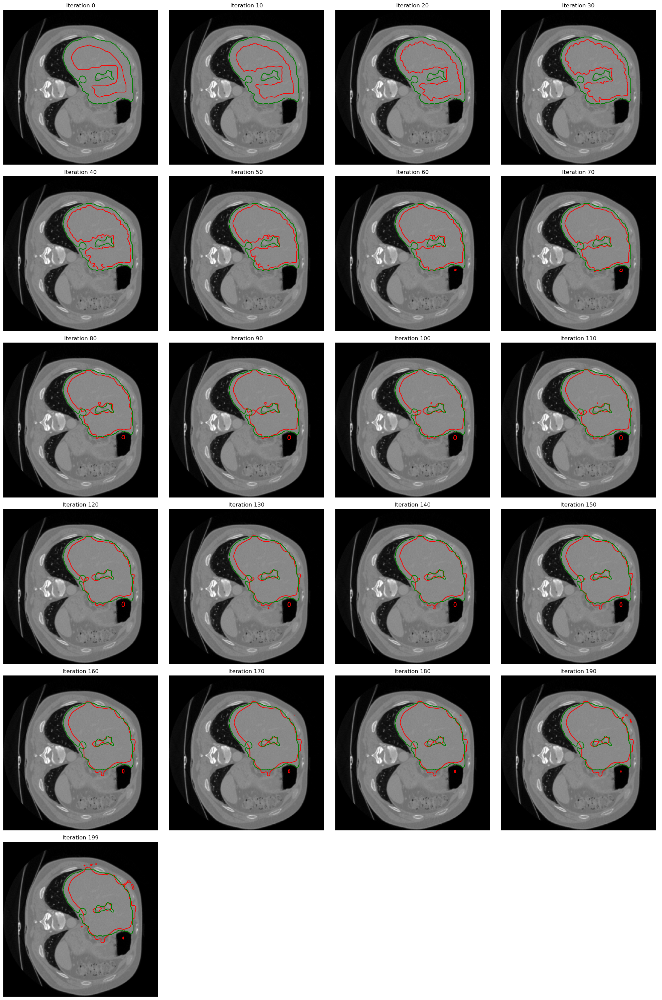

In [54]:
phi_init = mask_to_signed_distance(inner_mask)

phi_final = evolve_level_set(phi_init,
                             contrast_map,
                             homogeneity_map,
                             img_resized,
                             gt_mask,
                             alpha=1.0, beta=1.0, gamma=1.0,
                             timestep=0.3,
                             iterations=200,
                             visualize_every=10,
                             force_mask=force_mask)



In [55]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import numpy as np
import cv2

def evolve_level_set(phi, contrast_map, homogeneity_map, img_resized, gt_mask,
                     pred_binary=None,
                     alpha=1.0, beta=1.2, gamma=1.0,
                     timestep=0.1, iterations=200, visualize_every=10):
    """
    Evolve φ using texture-based level set with curvature regularization.
    Shows φ=0 and ground truth contours. Adds masking to restrict expansion.
    """
    snapshots = []

    # Create a mask that restricts forces to a zone around the predicted liver
    if pred_binary is not None:
        kernel = np.ones((25, 25), np.uint8)
        force_mask = cv2.dilate(pred_binary.astype(np.uint8), kernel, iterations=1)
    else:
        force_mask = np.ones_like(phi)

    for i in range(iterations):
        kappa = compute_curvature(phi)

        # External force, masked to liver region
        F_ext = (alpha * contrast_map - beta * homogeneity_map) * force_mask

        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt

        # Optional smoothing every few steps
        if i % 5 == 0:
            phi = gaussian_filter(phi, sigma=1)

        # Optional clamping
        phi = np.clip(phi, -1000, 1000)

        # Save snapshots for visualization
        if i % visualize_every == 0 or i == iterations - 1:
            snapshots.append((i, phi.copy()))

    # Plot results in grid (3 per row)
    cols = 3
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))

    for idx, (i, phi_snapshot) in enumerate(snapshots):
        ax = axes[idx // cols, idx % cols]
        ax.imshow(img_resized, cmap='gray')
        ax.contour(phi_snapshot, levels=[0], colors='r', linewidths=1.5)
        ax.contour(gt_mask.squeeze(), levels=[0.5], colors='g', linewidths=1.5)
        ax.set_title(f"Iteration {i}")
        ax.axis('off')

    for idx in range(len(snapshots), rows * cols):
        axes[idx // cols, idx % cols].axis('off')

    plt.tight_layout()
    plt.show()

    return phi


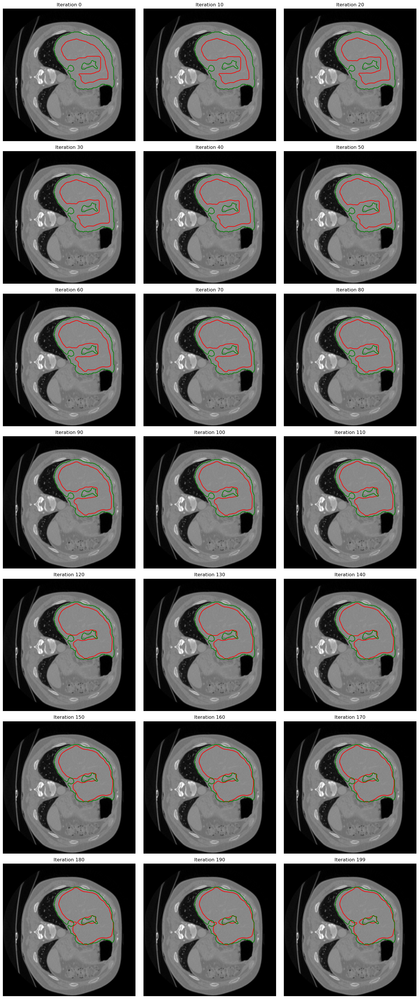

In [57]:
phi_init = mask_to_signed_distance(inner_mask)

phi_final = evolve_level_set(phi_init,
                             contrast_map,
                             homogeneity_map,
                             img_resized,
                             gt_mask,
                             pred_binary=pred_binary,  # needed for force_mask
                             alpha=1.0, beta=1.2, gamma=1.0,
                             timestep=0.1,
                             iterations=200,
                             visualize_every=10)


In [66]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import cv2
from sklearn.metrics import jaccard_score
from scipy.ndimage import distance_transform_edt, gaussian_filter
import time

# --- Evaluation metrics ---
def dice_score(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return 2. * intersection / (pred.sum() + true.sum() + 1e-8)

def iou_score(pred, true):
    pred_flat = pred.astype(np.uint8).flatten()
    true_flat = true.astype(np.uint8).flatten()
    return jaccard_score(true_flat, pred_flat, average='binary')

# --- Curvature-based level set evolution ---
def evolve_curvature_level_set(phi, contrast_map, homogeneity_map, force_mask,
                                alpha=1.0, beta=1.0, gamma=1.0,
                                timestep=0.1, iterations=200):
    def compute_curvature(phi):
        phi_y, phi_x = np.gradient(phi)
        norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
        nx = phi_x / norm
        ny = phi_y / norm
        nxx = np.gradient(nx, axis=1)
        nyy = np.gradient(ny, axis=0)
        return nxx + nyy

    for _ in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = (alpha * contrast_map - beta * homogeneity_map) * force_mask
        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt
        phi = gaussian_filter(phi, sigma=1)
        phi = np.clip(phi, -1000, 1000)

    return (phi < 0).astype(np.uint8)

# --- Evaluation loop ---
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)
results = []

for idx, (image, gt_mask) in enumerate(test_loader):

    start_time = time.time()  # ← Put this before the loop

    # Prepare data
    image_np = image.squeeze(0).numpy()
    gt_mask_np = gt_mask.squeeze(0).numpy()

    with torch.no_grad():
        # Ensure input is 4D: [B, C, H, W]
        if image.dim() == 2:
            input_tensor = image.unsqueeze(0).unsqueeze(0)  # [1, 1, H, W]
        elif image.dim() == 3:
            input_tensor = image.unsqueeze(0)  # [1, C, H, W]
        else:
            input_tensor = image  # already correct shape
        
        input_tensor = input_tensor.float().to(next(model.parameters()).device)

        pred = model(input_tensor).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    # Erode to get inner mask
    kernel = np.ones((5, 5), np.uint8)
    inner_mask = cv2.erode(pred_binary, kernel, iterations=1)

    # Force mask (for constraint)
    force_mask = cv2.dilate(pred_binary, np.ones((25, 25), np.uint8), iterations=1).astype(np.float32)

    # Signed distance
    phi_init = distance_transform_edt(inner_mask == 0) - distance_transform_edt(inner_mask)

    # GLCM features
    image_np = image.squeeze().cpu().numpy()
    feature_maps = compute_glcm_feature_maps(image_np)
    contrast_map = feature_maps["contrast"]
    homogeneity_map = feature_maps["homogeneity"]

    # Run curvature-based level set
    final_mask = evolve_curvature_level_set(phi_init, contrast_map, homogeneity_map, force_mask)

    # Evaluate
    dice = dice_score(final_mask, gt_mask_np)
    iou = iou_score(final_mask, gt_mask_np)

    results.append({
        "slice_index": idx,
        "method": "curvature_only",
        "dice": dice,
        "iou": iou
    })

    elapsed = time.time() - start_time


    print(f"Processed slice {idx + 1} out of {len(combined_test)}, {elapsed}")


# --- Output to DataFrame ---
df_results = pd.DataFrame(results)
df_results.to_csv("curvature_level_set_results.csv", index=False)

Processed slice 1948 out of 2122, 8.618602275848389
Processed slice 1949 out of 2122, 8.470806360244751
Processed slice 1950 out of 2122, 8.560065507888794
Processed slice 1951 out of 2122, 8.634628057479858
Processed slice 1952 out of 2122, 8.623172283172607
Processed slice 1953 out of 2122, 8.785757541656494
Processed slice 1954 out of 2122, 8.421768188476562
Processed slice 1955 out of 2122, 8.623936176300049
Processed slice 1956 out of 2122, 8.70388126373291
Processed slice 1957 out of 2122, 8.482834100723267
Processed slice 1958 out of 2122, 8.583081245422363
Processed slice 1959 out of 2122, 8.559481620788574
Processed slice 1960 out of 2122, 8.59869122505188
Processed slice 1961 out of 2122, 8.557679891586304
Processed slice 1962 out of 2122, 8.642256259918213
Processed slice 1963 out of 2122, 8.530024528503418
Processed slice 1964 out of 2122, 8.630699157714844
Processed slice 1965 out of 2122, 8.573458433151245
Processed slice 1966 out of 2122, 8.544479131698608
Processed slic

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 2057 out of 2122, 8.617594957351685
Processed slice 2058 out of 2122, 8.380579948425293
Processed slice 2059 out of 2122, 8.501601696014404
Processed slice 2060 out of 2122, 8.417864084243774
Processed slice 2061 out of 2122, 8.535080432891846
Processed slice 2062 out of 2122, 8.479481935501099
Processed slice 2063 out of 2122, 8.530049085617065
Processed slice 2064 out of 2122, 8.464296817779541
Processed slice 2065 out of 2122, 8.585954666137695
Processed slice 2066 out of 2122, 8.506718397140503
Processed slice 2067 out of 2122, 8.45119047164917
Processed slice 2068 out of 2122, 8.696192741394043
Processed slice 2069 out of 2122, 8.472037315368652
Processed slice 2070 out of 2122, 8.590481519699097
Processed slice 2071 out of 2122, 8.410771369934082
Processed slice 2072 out of 2122, 8.596079111099243
Processed slice 2073 out of 2122, 8.43672227859497
Processed slice 2074 out of 2122, 8.47599744796753
Processed slice 2075 out of 2122, 8.52409029006958
Processed slice 

## Failure, compute-edged-force

In [244]:
torch.cuda.empty_cache()

In [28]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, sobel
import numpy as np
import cv2

def compute_edge_force(image):
    """
    Computes edge attraction force using Sobel gradient magnitude.
    Inverted and normalized.
    """
    Ix = sobel(image, axis=1)
    Iy = sobel(image, axis=0)
    grad_mag = np.sqrt(Ix**2 + Iy**2)
    
    # Normalize and invert
    grad_mag = (grad_mag - grad_mag.min()) / (grad_mag.max() - grad_mag.min() + 1e-8)
    return -grad_mag

def evolve_level_set(phi, contrast_map, homogeneity_map, img_resized, gt_mask,
                     pred_binary=None,
                     alpha=1.0, beta=1.2, gamma=1.0, delta=0.3,
                     timestep=0.1, iterations=200, visualize_every=10):
    """
    Evolve φ using texture + edge + curvature forces.
    """
    snapshots = []

    # Edge attraction force
    edge_force = compute_edge_force(img_resized)

    # Create a mask to localize evolution
    if pred_binary is not None:
        kernel = np.ones((25, 25), np.uint8)
        force_mask = cv2.dilate(pred_binary.astype(np.uint8), kernel, iterations=1)
    else:
        force_mask = np.ones_like(phi)

    for i in range(iterations):
        kappa = compute_curvature(phi)

        # External force including GLCM + edge snapping
        F_ext = (alpha * contrast_map - beta * homogeneity_map + delta * edge_force) * force_mask

        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt

        # Optional smoothing
        if i % 5 == 0:
            phi = gaussian_filter(phi, sigma=1)

        phi = np.clip(phi, -1000, 1000)

        if i % visualize_every == 0 or i == iterations - 1:
            snapshots.append((i, phi.copy()))

    # Plot in grid (3 per row)
    cols = 3
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    
    # Flatten axes to 1D list for safe indexing
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]
    
    for idx, (i, phi_snapshot) in enumerate(snapshots):
        ax = axes[idx]
        ax.imshow(img_resized, cmap='gray')
        ax.contour(phi_snapshot, levels=[0], colors='r', linewidths=1.5)
        ax.contour(gt_mask.squeeze(), levels=[0.5], colors='g', linewidths=1.5)
        ax.set_title(f"Iteration {i}")
        ax.axis('off')
    
    # Hide unused subplots
    for idx in range(len(snapshots), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()



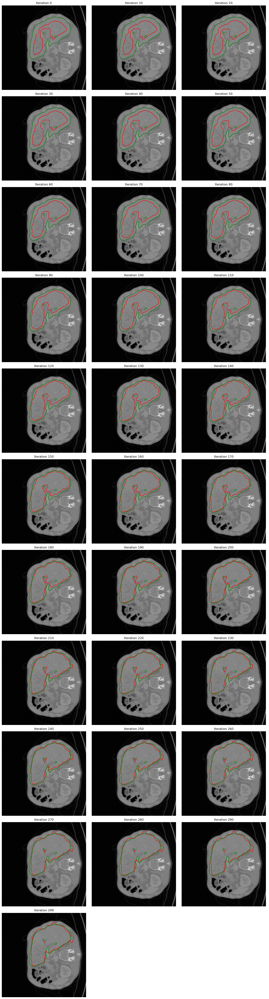

In [29]:
phi_init = mask_to_signed_distance(inner_mask)

phi_final = evolve_level_set(phi_init,
                             contrast_map,
                             homogeneity_map,
                             img_resized,
                             gt_mask,
                             pred_binary=pred_binary,
                             alpha=1.0, beta=1.2, gamma=1.0, delta=1.0,
                             timestep=0.1,
                             iterations=300,
                             visualize_every=10)


In [72]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import cv2
import time
from sklearn.metrics import jaccard_score
from scipy.ndimage import distance_transform_edt, gaussian_filter, sobel

# --- Evaluation metrics ---
def dice_score(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return 2. * intersection / (pred.sum() + true.sum() + 1e-8)

def iou_score(pred, true):
    pred_flat = pred.astype(np.uint8).flatten()
    true_flat = true.astype(np.uint8).flatten()
    return jaccard_score(true_flat, pred_flat, average='binary')

# --- Edge-based level set evolution ---
def evolve_edge_level_set(phi, edge_stop, force_mask,
                          alpha=1.0, gamma=1.0,
                          timestep=0.1, iterations=200):
    phi = phi.squeeze()
    edge_stop = edge_stop.squeeze()
    force_mask = force_mask.squeeze()

    
    def compute_curvature(phi):
        phi_y, phi_x = np.gradient(phi)
        norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
        nx = phi_x / norm
        ny = phi_y / norm
        nxx = np.gradient(nx, axis=1)
        nyy = np.gradient(ny, axis=0)
        return nxx + nyy

    for _ in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = (alpha * edge_stop) * force_mask
        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt
        phi = gaussian_filter(phi, sigma=1)
        phi = np.clip(phi, -1000, 1000)

    return (phi < 0).astype(np.uint8)

# --- Evaluation loop ---
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)
results = []

for idx, (image, gt_mask) in enumerate(test_loader):
    start_time = time.time()

    # Prepare data
    image_np = image.squeeze(0).numpy()
    gt_mask_np = gt_mask.squeeze(0).numpy()

    with torch.no_grad():
        if image.dim() == 2:
            input_tensor = image.unsqueeze(0).unsqueeze(0)  # [1, 1, H, W]
        elif image.dim() == 3:
            input_tensor = image.unsqueeze(0)  # [1, C, H, W]
        else:
            input_tensor = image

        input_tensor = input_tensor.float().to(next(model.parameters()).device)
        pred = model(input_tensor).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    # Inner mask (for φ init)
    kernel = np.ones((5, 5), np.uint8)
    inner_mask = cv2.erode(pred_binary, kernel, iterations=1)

    # Force mask (outer dilation)
    force_mask = cv2.dilate(pred_binary, np.ones((25, 25), np.uint8), iterations=1).astype(np.float32)

    # Signed distance
    phi_init = (distance_transform_edt(inner_mask == 0) - distance_transform_edt(inner_mask)).squeeze()

    # Edge map (stopping function)
    img_smooth = gaussian_filter(image_np, sigma=1)
    grad_x = sobel(img_smooth, axis=1)
    grad_y = sobel(img_smooth, axis=0)
    grad_mag = np.sqrt(grad_x**2 + grad_y**2)
    grad_mag = (grad_mag - grad_mag.min()) / (grad_mag.max() - grad_mag.min() + 1e-8)
    edge_stop = 1.0 / (1.0 + grad_mag)

    # Run level set
    final_mask = evolve_edge_level_set(phi_init, edge_stop, force_mask)

    # Evaluate
    dice = dice_score(final_mask, gt_mask_np)
    iou = iou_score(final_mask, gt_mask_np)

    results.append({
        "slice_index": idx,
        "method": "edge_force",
        "dice": dice,
        "iou": iou
    })

    elapsed = time.time() - start_time
    print(f"Processed slice {idx + 1} out of {len(combined_test)}, {elapsed:.2f} sec")

# --- Save results ---
df_results = pd.DataFrame(results)
df_results.to_csv("edge_level_set_results.csv", index=False)


Processed slice 1263 out of 2122, 0.41 sec
Processed slice 1264 out of 2122, 0.38 sec
Processed slice 1265 out of 2122, 0.41 sec
Processed slice 1266 out of 2122, 0.45 sec
Processed slice 1267 out of 2122, 0.45 sec
Processed slice 1268 out of 2122, 0.42 sec
Processed slice 1269 out of 2122, 0.41 sec
Processed slice 1270 out of 2122, 0.43 sec
Processed slice 1271 out of 2122, 0.43 sec
Processed slice 1272 out of 2122, 0.40 sec
Processed slice 1273 out of 2122, 0.44 sec
Processed slice 1274 out of 2122, 0.41 sec
Processed slice 1275 out of 2122, 0.43 sec
Processed slice 1276 out of 2122, 0.37 sec
Processed slice 1277 out of 2122, 0.38 sec
Processed slice 1278 out of 2122, 0.37 sec
Processed slice 1279 out of 2122, 0.39 sec
Processed slice 1280 out of 2122, 0.43 sec
Processed slice 1281 out of 2122, 0.38 sec
Processed slice 1282 out of 2122, 0.38 sec
Processed slice 1283 out of 2122, 0.40 sec
Processed slice 1284 out of 2122, 0.37 sec
Processed slice 1285 out of 2122, 0.43 sec
Processed s

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 1553 out of 2122, 0.41 sec
Processed slice 1554 out of 2122, 0.42 sec
Processed slice 1555 out of 2122, 0.42 sec
Processed slice 1556 out of 2122, 0.42 sec
Processed slice 1557 out of 2122, 0.41 sec
Processed slice 1558 out of 2122, 0.41 sec
Processed slice 1559 out of 2122, 0.41 sec
Processed slice 1560 out of 2122, 0.45 sec
Processed slice 1561 out of 2122, 0.44 sec
Processed slice 1562 out of 2122, 0.40 sec
Processed slice 1563 out of 2122, 0.37 sec
Processed slice 1564 out of 2122, 0.38 sec
Processed slice 1565 out of 2122, 0.37 sec
Processed slice 1566 out of 2122, 0.41 sec
Processed slice 1567 out of 2122, 0.42 sec
Processed slice 1568 out of 2122, 0.42 sec
Processed slice 1569 out of 2122, 0.43 sec
Processed slice 1570 out of 2122, 0.42 sec
Processed slice 1571 out of 2122, 0.41 sec
Processed slice 1572 out of 2122, 0.42 sec
Processed slice 1573 out of 2122, 0.42 sec
Processed slice 1574 out of 2122, 0.42 sec
Processed slice 1575 out of 2122, 0.41 sec
Processed s

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 1865 out of 2122, 0.38 sec
Processed slice 1866 out of 2122, 0.37 sec
Processed slice 1867 out of 2122, 0.40 sec
Processed slice 1868 out of 2122, 0.41 sec
Processed slice 1869 out of 2122, 0.42 sec
Processed slice 1870 out of 2122, 0.42 sec
Processed slice 1871 out of 2122, 0.41 sec
Processed slice 1872 out of 2122, 0.41 sec
Processed slice 1873 out of 2122, 0.41 sec
Processed slice 1874 out of 2122, 0.42 sec
Processed slice 1875 out of 2122, 0.41 sec
Processed slice 1876 out of 2122, 0.42 sec
Processed slice 1877 out of 2122, 0.40 sec
Processed slice 1878 out of 2122, 0.42 sec
Processed slice 1879 out of 2122, 0.41 sec
Processed slice 1880 out of 2122, 0.40 sec
Processed slice 1881 out of 2122, 0.42 sec
Processed slice 1882 out of 2122, 0.42 sec
Processed slice 1883 out of 2122, 0.43 sec
Processed slice 1884 out of 2122, 0.46 sec
Processed slice 1885 out of 2122, 0.39 sec
Processed slice 1886 out of 2122, 0.37 sec
Processed slice 1887 out of 2122, 0.37 sec
Processed s

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 2057 out of 2122, 0.36 sec
Processed slice 2058 out of 2122, 0.37 sec
Processed slice 2059 out of 2122, 0.38 sec
Processed slice 2060 out of 2122, 0.37 sec
Processed slice 2061 out of 2122, 0.43 sec
Processed slice 2062 out of 2122, 0.42 sec
Processed slice 2063 out of 2122, 0.40 sec
Processed slice 2064 out of 2122, 0.41 sec
Processed slice 2065 out of 2122, 0.42 sec
Processed slice 2066 out of 2122, 0.42 sec
Processed slice 2067 out of 2122, 0.42 sec
Processed slice 2068 out of 2122, 0.43 sec
Processed slice 2069 out of 2122, 0.41 sec
Processed slice 2070 out of 2122, 0.42 sec
Processed slice 2071 out of 2122, 0.37 sec
Processed slice 2072 out of 2122, 0.36 sec
Processed slice 2073 out of 2122, 0.37 sec
Processed slice 2074 out of 2122, 0.38 sec
Processed slice 2075 out of 2122, 0.43 sec
Processed slice 2076 out of 2122, 0.43 sec
Processed slice 2077 out of 2122, 0.41 sec
Processed slice 2078 out of 2122, 0.43 sec
Processed slice 2079 out of 2122, 0.47 sec
Processed s

## Failure, Gradient based stopping function

In [31]:
def compute_stopping_function(image):
    """
    Computes g(|∇I|) = 1 / (1 + |∇I|^2) to slow evolution near edges.
    """
    Ix = sobel(image, axis=1)
    Iy = sobel(image, axis=0)
    grad_mag = np.sqrt(Ix**2 + Iy**2)

    # Normalize grad to [0, 1]
    grad_mag = grad_mag / (grad_mag.max() + 1e-8)
    g = 1 / (1 + grad_mag**2)  # stopping function

    return g


In [32]:
def evolve_level_set(phi, contrast_map, homogeneity_map, img_resized, gt_mask,
                     pred_binary=None,
                     alpha=1.0, beta=1.2, gamma=1.0,
                     timestep=0.1, iterations=200, visualize_every=10):
    """
    Level set with GLCM features and gradient-based stopping function.
    """
    snapshots = []

    # Compute edge stopping function
    g = compute_stopping_function(img_resized)

    # Force mask around liver
    if pred_binary is not None:
        kernel = np.ones((25, 25), np.uint8)
        force_mask = cv2.dilate(pred_binary.astype(np.uint8), kernel, iterations=1)
    else:
        force_mask = np.ones_like(phi)

    for i in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = alpha * contrast_map - beta * homogeneity_map

        # Total update with stopping function
        dphi_dt = g * (F_ext - gamma * kappa) * force_mask
        phi += timestep * dphi_dt

        if i % 5 == 0:
            phi = gaussian_filter(phi, sigma=1)

        phi = np.clip(phi, -1000, 1000)

        if i % visualize_every == 0 or i == iterations - 1:
            snapshots.append((i, phi.copy()))

    # Plot results
    cols = 3
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))

    for idx, (i, phi_snapshot) in enumerate(snapshots):
        ax = axes[idx // cols, idx % cols]
        ax.imshow(img_resized, cmap='gray')
        ax.contour(phi_snapshot, levels=[0], colors='r', linewidths=1.5)
        ax.contour(gt_mask.squeeze(), levels=[0.5], colors='g', linewidths=1.5)
        ax.set_title(f"Iteration {i}")
        ax.axis('off')

    for idx in range(len(snapshots), rows * cols):
        axes[idx // cols, idx % cols].axis('off')

    plt.tight_layout()
    plt.show()

    return phi


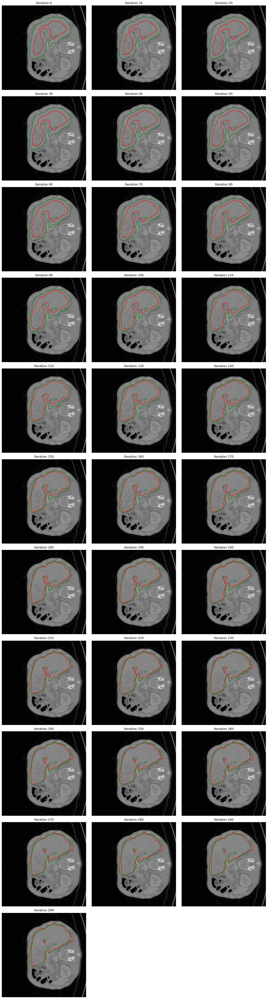

In [33]:
phi_final = evolve_level_set(phi_init,
                             contrast_map,
                             homogeneity_map,
                             img_resized,
                             gt_mask,
                             pred_binary=pred_binary,
                             alpha=1.0, beta=1.2, gamma=1.0,
                             timestep=0.1,
                             iterations=300,
                             visualize_every=10)


In [ ]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import cv2
from sklearn.metrics import jaccard_score
from scipy.ndimage import distance_transform_edt, gaussian_filter
import time

# --- Evaluation metrics ---
def dice_score(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return 2. * intersection / (pred.sum() + true.sum() + 1e-8)

def iou_score(pred, true):
    pred_flat = pred.astype(np.uint8).flatten()
    true_flat = true.astype(np.uint8).flatten()
    return jaccard_score(true_flat, pred_flat, average='binary')

# --- Level set with gradient-based stopping ---
def evolve_gradient_level_set(phi, contrast_map, homogeneity_map, force_mask,
                               alpha=1.0, beta=1.0, gamma=1.0,
                               timestep=0.1, iterations=200):
    def compute_curvature(phi):
        phi_y, phi_x = np.gradient(phi)
        norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
        nx = phi_x / norm
        ny = phi_y / norm
        nxx = np.gradient(nx, axis=1)
        nyy = np.gradient(ny, axis=0)
        return nxx + nyy

    for _ in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = (alpha * contrast_map - beta * homogeneity_map) * force_mask
        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt
        phi = gaussian_filter(phi, sigma=1)
        phi = np.clip(phi, -1000, 1000)

    return (phi < 0).astype(np.uint8)

# --- Evaluation loop ---
results = []
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)

for idx, (image, gt_mask) in enumerate(test_loader):
    start_time = time.time()

    image = image.squeeze()
    gt_mask = gt_mask.squeeze()

    input_tensor = image.unsqueeze(0).unsqueeze(0).float().to(next(model.parameters()).device)

    with torch.no_grad():
        pred = model(input_tensor).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    gt_mask_np = gt_mask.cpu().numpy().astype(np.uint8)

    # Inner and force mask
    inner_mask = cv2.erode(pred_binary, np.ones((5, 5), np.uint8), iterations=1)
    force_mask = cv2.dilate(pred_binary, np.ones((25, 25), np.uint8), iterations=1).astype(np.float32)

    # Initialize phi
    phi_init = distance_transform_edt(inner_mask == 0) - distance_transform_edt(inner_mask)

    # Compute GLCM features
    image_np = image.cpu().numpy()
    feature_maps = compute_glcm_feature_maps(image_np)
    contrast_map = feature_maps["contrast"]
    homogeneity_map = feature_maps["homogeneity"]

    # Evolve
    final_mask = evolve_gradient_level_set(phi_init, contrast_map, homogeneity_map, force_mask)

    # Evaluate
    dice = dice_score(final_mask, gt_mask_np)
    iou = iou_score(final_mask, gt_mask_np)

    results.append({
        "slice_index": idx,
        "method": "gradient_based",
        "dice": dice,
        "iou": iou
    })

    elapsed = time.time() - start_time
    print(f"Processed slice {idx+1} of {len(combined_test)}, Time: {elapsed:.2f} sec")

# Save to CSV
df = pd.DataFrame(results)
df.to_csv("gradient_level_set_results.csv", index=False)


## Region based energy

In [35]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import numpy as np
import cv2

def compute_curvature(phi):
    """
    Computes the curvature of φ using normalized gradient divergence.
    """
    phi_y, phi_x = np.gradient(phi)
    norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
    nx = phi_x / norm
    ny = phi_y / norm
    nxx = np.gradient(nx, axis=1)
    nyy = np.gradient(ny, axis=0)
    return nxx + nyy

def compute_region_force(phi, image, lambda1=1.0, lambda2=1.0):
    """
    Chan-Vese region-based energy using inside/outside means.
    """
    inside = phi < 0
    outside = ~inside

    # Avoid degenerate cases
    if np.sum(inside) < 10 or np.sum(outside) < 10:
        return np.zeros_like(image)

    c1 = np.mean(image[inside])
    c2 = np.mean(image[outside])

    region_force = lambda1 * (image - c1)**2 - lambda2 * (image - c2)**2
    return region_force

def evolve_level_set(phi, contrast_map, homogeneity_map, img_resized, gt_mask,
                     pred_binary=None,
                     alpha=1.0, beta=1.2, gamma=1.0, theta=0.5,
                     timestep=0.1, iterations=200, visualize_every=10):
    """
    Evolve φ using texture + region-based energy + curvature.
    """
    snapshots = []

    # Optional: restrict forces to liver region
    if pred_binary is not None:
        kernel = np.ones((25, 25), np.uint8)
        force_mask = cv2.dilate(pred_binary.astype(np.uint8), kernel, iterations=1)
    else:
        force_mask = np.ones_like(phi)

    for i in range(iterations):
        kappa = compute_curvature(phi)
        region_force = compute_region_force(phi, img_resized)

        # Total force
        F_ext = (alpha * contrast_map
                 - beta * homogeneity_map
                 + theta * region_force) * force_mask

        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt

        if i % 5 == 0:
            phi = gaussian_filter(phi, sigma=1)

        phi = np.clip(phi, -1000, 1000)

        if i % visualize_every == 0 or i == iterations - 1:
            snapshots.append((i, phi.copy()))

    # Plot results
    cols = 3
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))

    for idx, (i, phi_snapshot) in enumerate(snapshots):
        ax = axes[idx // cols, idx % cols]
        ax.imshow(img_resized, cmap='gray')
        ax.contour(phi_snapshot, levels=[0], colors='r', linewidths=1.5)
        ax.contour(gt_mask.squeeze(), levels=[0.5], colors='g', linewidths=1.5)
        ax.set_title(f"Iteration {i}")
        ax.axis('off')

    for idx in range(len(snapshots), rows * cols):
        axes[idx // cols, idx % cols].axis('off')

    plt.tight_layout()
    plt.show()

    return phi


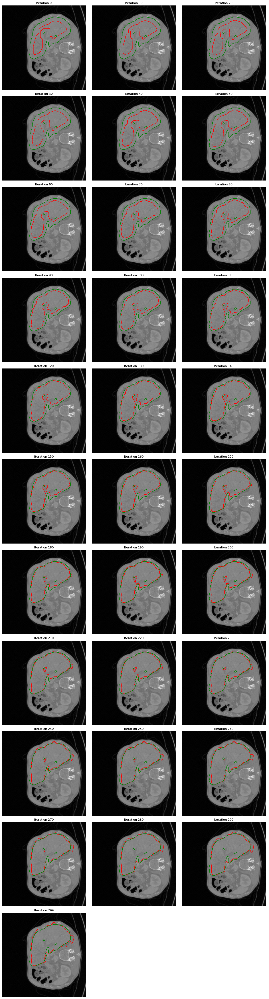

In [36]:
phi_final = evolve_level_set(phi_init,
                             contrast_map,
                             homogeneity_map,
                             img_resized,
                             gt_mask,
                             pred_binary=pred_binary,
                             alpha=1.0, beta=1.2, gamma=1.0, theta=1.0,
                             timestep=0.1,
                             iterations=300,
                             visualize_every=10)


In [82]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import pandas as pd
import cv2
from sklearn.metrics import jaccard_score
from scipy.ndimage import distance_transform_edt, gaussian_filter
import time

# --- Evaluation metrics ---
def dice_score(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return 2. * intersection / (pred.sum() + true.sum() + 1e-8)

def iou_score(pred, true):
    pred_flat = pred.astype(np.uint8).flatten()
    true_flat = true.astype(np.uint8).flatten()
    return jaccard_score(true_flat, pred_flat, average='binary')

# --- Region-based level set evolution ---
def evolve_region_level_set(phi, image, contrast_map, homogeneity_map, force_mask,
                            alpha=1.0, beta=1.0, gamma=1.0, theta=1.0,
                            timestep=0.1, iterations=200):
    def compute_curvature(phi):
        phi_y, phi_x = np.gradient(phi)
        norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
        nx = phi_x / norm
        ny = phi_y / norm
        nxx = np.gradient(nx, axis=1)
        nyy = np.gradient(ny, axis=0)
        return nxx + nyy

    for _ in range(iterations):
        inside = phi < 0
        outside = ~inside
        c_in = image[inside].mean() if np.any(inside) else 0.0
        c_out = image[outside].mean() if np.any(outside) else 0.0
        region_force = -theta * ((image - c_in)**2 - (image - c_out)**2)

        kappa = compute_curvature(phi)
        F_ext = (alpha * contrast_map - beta * homogeneity_map + region_force) * force_mask
        dphi_dt = F_ext - gamma * kappa
        phi += timestep * dphi_dt
        phi = gaussian_filter(phi, sigma=1)
        phi = np.clip(phi, -1000, 1000)

    return (phi < 0).astype(np.uint8)

# --- Evaluation loop ---
results = []
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)

for idx, (image, gt_mask) in enumerate(test_loader):
    start_time = time.time()

    image = image.squeeze()
    gt_mask = gt_mask.squeeze()

    input_tensor = image.unsqueeze(0).unsqueeze(0).float().to(next(model.parameters()).device)

    with torch.no_grad():
        pred = model(input_tensor).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    gt_mask_np = gt_mask.cpu().numpy().astype(np.uint8)

    # Inner and force mask
    inner_mask = cv2.erode(pred_binary, np.ones((5, 5), np.uint8), iterations=1)
    force_mask = cv2.dilate(pred_binary, np.ones((25, 25), np.uint8), iterations=1).astype(np.float32)

    # Initialize phi
    phi_init = distance_transform_edt(inner_mask == 0) - distance_transform_edt(inner_mask)

    # Compute GLCM features
    image_np = image.cpu().numpy()
    feature_maps = compute_glcm_feature_maps(image_np)
    contrast_map = feature_maps["contrast"]
    homogeneity_map = feature_maps["homogeneity"]

    # Evolve
    final_mask = evolve_region_level_set(phi_init, image_np, contrast_map, homogeneity_map, force_mask)

    # Evaluate
    dice = dice_score(final_mask, gt_mask_np)
    iou = iou_score(final_mask, gt_mask_np)

    results.append({
        "slice_index": idx,
        "method": "region_based",
        "dice": dice,
        "iou": iou
    })

    elapsed = time.time() - start_time
    print(f"Processed slice {idx+1} of {len(combined_test)}, Time: {elapsed:.2f} sec")

# Save to CSV
df = pd.DataFrame(results)
df.to_csv("region_level_set_results.csv", index=False)


Processed slice 1 of 2122, Time: 8.70 sec
Processed slice 2 of 2122, Time: 8.56 sec
Processed slice 3 of 2122, Time: 8.54 sec
Processed slice 4 of 2122, Time: 8.54 sec
Processed slice 5 of 2122, Time: 8.54 sec
Processed slice 6 of 2122, Time: 8.56 sec
Processed slice 7 of 2122, Time: 8.49 sec
Processed slice 8 of 2122, Time: 8.48 sec
Processed slice 9 of 2122, Time: 8.65 sec
Processed slice 10 of 2122, Time: 8.40 sec
Processed slice 11 of 2122, Time: 8.67 sec
Processed slice 12 of 2122, Time: 8.43 sec
Processed slice 13 of 2122, Time: 8.55 sec
Processed slice 14 of 2122, Time: 8.65 sec
Processed slice 15 of 2122, Time: 8.61 sec
Processed slice 16 of 2122, Time: 8.72 sec
Processed slice 17 of 2122, Time: 8.61 sec
Processed slice 18 of 2122, Time: 8.59 sec
Processed slice 19 of 2122, Time: 8.52 sec
Processed slice 20 of 2122, Time: 8.49 sec
Processed slice 21 of 2122, Time: 8.42 sec
Processed slice 22 of 2122, Time: 8.64 sec
Processed slice 23 of 2122, Time: 8.49 sec
Processed slice 24 o

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 1553 of 2122, Time: 8.57 sec
Processed slice 1554 of 2122, Time: 8.46 sec
Processed slice 1555 of 2122, Time: 8.57 sec
Processed slice 1556 of 2122, Time: 8.51 sec
Processed slice 1557 of 2122, Time: 8.77 sec
Processed slice 1558 of 2122, Time: 8.45 sec
Processed slice 1559 of 2122, Time: 8.48 sec
Processed slice 1560 of 2122, Time: 8.40 sec
Processed slice 1561 of 2122, Time: 8.50 sec
Processed slice 1562 of 2122, Time: 8.58 sec
Processed slice 1563 of 2122, Time: 8.56 sec
Processed slice 1564 of 2122, Time: 8.56 sec
Processed slice 1565 of 2122, Time: 8.50 sec
Processed slice 1566 of 2122, Time: 8.53 sec
Processed slice 1567 of 2122, Time: 8.44 sec
Processed slice 1568 of 2122, Time: 8.59 sec
Processed slice 1569 of 2122, Time: 8.43 sec
Processed slice 1570 of 2122, Time: 8.49 sec
Processed slice 1571 of 2122, Time: 8.63 sec
Processed slice 1572 of 2122, Time: 8.47 sec
Processed slice 1573 of 2122, Time: 8.43 sec
Processed slice 1574 of 2122, Time: 8.62 sec
Processed 

C:\Users\Student\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Processed slice 2057 of 2122, Time: 8.44 sec
Processed slice 2058 of 2122, Time: 8.55 sec
Processed slice 2059 of 2122, Time: 8.49 sec
Processed slice 2060 of 2122, Time: 8.50 sec
Processed slice 2061 of 2122, Time: 8.44 sec
Processed slice 2062 of 2122, Time: 8.73 sec
Processed slice 2063 of 2122, Time: 8.47 sec
Processed slice 2064 of 2122, Time: 8.64 sec
Processed slice 2065 of 2122, Time: 8.58 sec
Processed slice 2066 of 2122, Time: 8.64 sec
Processed slice 2067 of 2122, Time: 8.49 sec
Processed slice 2068 of 2122, Time: 8.44 sec
Processed slice 2069 of 2122, Time: 8.53 sec
Processed slice 2070 of 2122, Time: 8.49 sec
Processed slice 2071 of 2122, Time: 8.66 sec
Processed slice 2072 of 2122, Time: 8.53 sec
Processed slice 2073 of 2122, Time: 8.70 sec
Processed slice 2074 of 2122, Time: 8.52 sec
Processed slice 2075 of 2122, Time: 8.77 sec
Processed slice 2076 of 2122, Time: 8.87 sec
Processed slice 2077 of 2122, Time: 8.68 sec
Processed slice 2078 of 2122, Time: 8.47 sec
Processed 

In [94]:
import torch
from torch.utils.data import DataLoader, Subset
import numpy as np
import pandas as pd
import cv2
import time
from sklearn.metrics import jaccard_score
from scipy.ndimage import distance_transform_edt, gaussian_filter, sobel

# --- Metric Functions ---
def dice_score(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)
    intersection = np.logical_and(pred, true).sum()
    return 2. * intersection / (pred.sum() + true.sum() + 1e-8)

def iou_score(pred, true):
    pred_flat = pred.astype(np.uint8).flatten()
    true_flat = true.astype(np.uint8).flatten()
    return jaccard_score(true_flat, pred_flat, average='binary')

# --- Gradient-Based Level Set Evolution (without force mask) ---
def evolve_gradient_level_set(phi, contrast_map, homogeneity_map,
                               alpha=1.0, beta=1.2, gamma=1.0,
                               timestep=0.1, iterations=200):
    def compute_curvature(phi):
        phi_y, phi_x = np.gradient(phi)
        norm = np.sqrt(phi_x**2 + phi_y**2 + 1e-8)
        nx = phi_x / norm
        ny = phi_y / norm
        nxx = np.gradient(nx, axis=1)
        nyy = np.gradient(ny, axis=0)
        return nxx + nyy

    for _ in range(iterations):
        kappa = compute_curvature(phi)
        F_ext = (alpha * contrast_map - beta * homogeneity_map)
        dphi_dt = F_ext - gamma * kappa
        dphi_dt = np.squeeze(dphi_dt)
        phi += timestep * dphi_dt
        phi = gaussian_filter(phi, sigma=1)
        phi = np.clip(phi, -1000, 1000)

    return (phi < 0).astype(np.uint8)

# --- Assume model is loaded and combined_test is prepared ---
test_loader = DataLoader(combined_test, batch_size=1, shuffle=False)
results = []
leak_threshold = 1000  # pixels — tune this based on your image size

for idx, (image, gt_mask) in enumerate(test_loader):
    if idx >= 300:  # ~30 slices per volume × 10 volumes
        break

    start_time = time.time()

    image = image.squeeze(0)  # [1, 256, 256] → [256, 256]
    gt_mask = gt_mask.squeeze(0).numpy()

    with torch.no_grad():
        input_tensor = image.unsqueeze(0).float().to(next(model.parameters()).device)
        pred = model(input_tensor).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    # Create signed distance function from inner region
    kernel = np.ones((5, 5), np.uint8)
    inner_mask = cv2.erode(pred_binary, kernel, iterations=1)
    phi_init = distance_transform_edt(inner_mask == 0) - distance_transform_edt(inner_mask)

    # GLCM feature maps (optional, if already defined in your notebook)
    contrast_map = np.ones_like(image.numpy(), dtype=np.float32)
    homogeneity_map = np.ones_like(image.numpy(), dtype=np.float32)

    # Evolve level set (no force mask)
    final_mask = evolve_gradient_level_set(phi_init, contrast_map, homogeneity_map)

    # Evaluate
    dice = dice_score(final_mask, gt_mask)
    iou = iou_score(final_mask, gt_mask)

    leak_pixels = np.sum((final_mask == 1) & (gt_mask == 0))
    leaked = leak_pixels > leak_threshold

    results.append({
        "slice_index": idx,
        "dice": dice,
        "iou": iou,
        "leaked": leaked,
        "leak_pixels": leak_pixels,
        "time_sec": time.time() - start_time
    })

    print(f"Slice {idx+1}: Dice={dice:.4f}, IOU={iou:.4f}, Leaked={leaked}, LeakSize={leak_pixels} px")

# --- Save Results ---
df = pd.DataFrame(results)
df.to_csv("leakage_eval_gradient_no_force.csv", index=False)


Slice 1: Dice=0.6895, IOU=0.5212, Leaked=False, LeakSize=0 px
Slice 2: Dice=0.0000, IOU=0.0000, Leaked=False, LeakSize=0 px
Slice 3: Dice=0.9112, IOU=0.8370, Leaked=False, LeakSize=247 px
Slice 4: Dice=0.9440, IOU=0.8908, Leaked=False, LeakSize=268 px
Slice 5: Dice=0.9045, IOU=0.8256, Leaked=False, LeakSize=2 px
Slice 6: Dice=0.8253, IOU=0.7199, Leaked=False, LeakSize=0 px
Slice 7: Dice=0.9220, IOU=0.8553, Leaked=False, LeakSize=384 px
Slice 8: Dice=0.9192, IOU=0.8505, Leaked=False, LeakSize=179 px
Slice 9: Dice=0.9780, IOU=0.9569, Leaked=False, LeakSize=174 px
Slice 10: Dice=0.0000, IOU=0.0000, Leaked=False, LeakSize=0 px
Slice 11: Dice=0.7405, IOU=0.5880, Leaked=False, LeakSize=0 px
Slice 12: Dice=0.9040, IOU=0.8229, Leaked=False, LeakSize=500 px
Slice 13: Dice=0.9265, IOU=0.4589, Leaked=False, LeakSize=261 px
Slice 14: Dice=0.8984, IOU=0.8133, Leaked=False, LeakSize=801 px
Slice 15: Dice=0.7108, IOU=0.5514, Leaked=False, LeakSize=0 px
Slice 16: Dice=0.9777, IOU=0.9565, Leaked=False,

KeyboardInterrupt: 